In [1]:
import fastf1 as f1
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math
import datetime
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, Normalizer, MinMaxScaler, LabelEncoder
from sklearn.metrics import mean_squared_error
from keras.api.callbacks import EarlyStopping

f1.Cache.enable_cache("C:\\Users\davix\AppData\Local\Temp\FastF1_cache")

In [ ]:
%load_ext tensorboard

In [2]:
df = pd.read_csv('F1_gp_tesi_official.csv')

FASE PULIZIA DATI

In [3]:
df = df[df['Compound'].notnull()]
df.fillna('0', inplace=True)
df = df.drop_duplicates()

In [4]:
# aggiustamento delle colonne con tipo Time
df['Sector1Time'] = (df['Sector1Time']).astype(float)
df['Sector2Time'] = (df['Sector2Time']).astype(float)
df['Sector3Time'] = (df['Sector3Time']).astype(float)
df['Time'] = (df['Time']).astype(float)

# aggiustamento delle colonne con tipo Integer
df['Stint'] = df['Stint'].astype(int)
df['LapNumber'] = df['LapNumber'].astype(int)
df['Compound'] = df['Compound'].astype(int)
df['TrackTemp'] = df['TrackTemp'].astype(float)
df['WindSpeed'] = df['WindSpeed'].astype(float)
df['WindDirection'] = df['WindDirection'].astype(float)
df['Humidity'] = df['Humidity'].astype(float)
df['AirTemp'] = df['AirTemp'].astype(float)
df['DriverNumber'] = df['DriverNumber'].astype(int)
df['Year'] = df['Year'].astype(int)
df['Round'] = df['Round'].astype(int)

# aggiustamento LapTime con tipo Float
df['tempo_td'] = pd.to_timedelta(df['LapTime'])
df['LapTime'] = df['tempo_td'].dt.total_seconds()
df = df.drop(columns=['tempo_td'])

# aggiustamento delle colonne con tipo String
df['TyreLife'] = df['TyreLife'].astype(str)
df['Position'] = df['Position'].astype(str)
df['TrackStatus'] = df['TrackStatus'].astype(str)
df['Driver'] = df['Driver'].astype(str)

df_final = df.drop_duplicates()

In [5]:
fields = ['LapNumber', 'LapTime', 'Round', 'Year', 'Event', 'DriverNumber', 'Position', 'TyreLife','TrackStatus','Rainfall','TrackTemp', 'AirTemp', 'Humidity', 'WindSpeed', 'WindDirection', 'Compound', 'Stint']

df_final = df_final[(df_final['Rainfall'] == 0) & ((df_final['Compound'] != 4) & (df_final['Compound'] != 5)) ]
df_final = df_final[fields]

In [7]:
# test raggruppando i dati per anno, gran premio, pilota e stint

df_groupie = df_final.groupby(['Year', 'Event', 'LapNumber'])['LapTime'].min().reset_index()

In [8]:
list_col = ['Year', 'Event', 'LapNumber', 'LapTime', 'Compound']
df_tmp = df_final[list_col]
df_best_tyre = pd.merge(df_tmp, df_groupie, on=['Year', 'Event', 'LapNumber', 'LapTime'], how='inner')
# df_best_tyre[(df_best_tyre['Year'] == '2019') & (df_best_tyre['Event'] == 'Melbourne')].sort_values(by='LapNumber', ascending=True)

In [ ]:
df_best_tyre = df_best_tyre[['Year', 'Event', 'LapNumber', 'Compound']]
df_best_tyre.rename(columns={
    'Compound': 'CompoundBest'
}, inplace=True)
df_best_tyre = df_best_tyre.drop_duplicates()

df_try = pd.merge(df_final, df_best_tyre, on=['Year', 'Event', 'LapNumber'], how='left')
df_try.head()

In [11]:
df_final = df_try.sort_values(by=['Year', 'Round', 'LapNumber', 'Stint', 'DriverNumber'], ascending=True)

In [ ]:
df_ready = pd.DataFrame()

for year in df_final['Year'].unique():
    print(year)
    df_temp = df_final[df_final['Year'] == year]
    for event in df_temp['Event'].unique():
        print(event)
        df_temp2 = df_temp[df_temp['Event'] == event]
        for driver in df_temp2['DriverNumber'].unique():
            print(driver)
            df_temp3 = df_temp2[df_temp2['DriverNumber'] == driver]
        
            while(df_temp3.LapNumber.max() < 78):
                lap = df_temp3.LapNumber.max() + 1
                new_row = {
                            'LapNumber': lap,
                            'LapTime': -1.0,
                            'Time': -1.0,
                            'TrackTemp': -1.0,
                            'Round': df_temp3['Round'].iloc[0],
                            'DriverNumber': driver,
                            'TyreLife': '-1.0',
                            'Position': '-1.0',
                            'TrackStatus': '-1.0',
                            'Rainfall': -1,
                            'Year': year,
                            'Event': event,
                            'Stint': -1,
                            'Compound': -1,
                            'CompoundBest': -1
                            }
                df_temp3.loc[lap] = new_row
            
            if df_ready.empty:
                df_ready = df_temp3
            else:
                df_ready = pd.concat([df_ready, df_temp3]) 

In [ ]:
df_final = df_ready

In [13]:
# partendo dal dataset originale filtro solo le gare ad alto carico aerodinamico
df = pd.DataFrame()

lista_year = [2019, 2020, 2021, 2022, 2023, 2024]
for year in lista_year:

    df_tmp = df_final[(df_final['Year'] == year)]

    if year == 2019:
        lista_nomi = [1, 6, 7, 12, 15, 18, 20]
    elif year == 2020:
        lista_nomi = [3, 12, 13]
    elif year == 2021:
        lista_nomi = [2, 3, 5, 11, 13, 18, 19]
    elif year == 2022:
        lista_nomi = [3, 4, 5, 7, 9, 13, 15, 17, 20]
    elif year == 2023:
        lista_nomi = [3, 5, 6, 8, 11, 13, 15, 19, 20]
    else:
        lista_nomi = [3, 6, 7, 8, 9, 13, 15, 18, 20]
    df_tmp = df_tmp[df_tmp['Round'].isin(lista_nomi)]

    if df.empty:
        df = df_tmp
    else:
        df = pd.concat([df, df_tmp])

In [143]:
# df = df.drop('Event', axis=1)
df['Round'] = df['Round'].astype(str)
df['Year'] = df['Year'].astype(str)

df['tmp'] = df['Round'].str.cat(df['Year'], sep='|')
df_train = df[(df['tmp'] != '20|2023')]
df_test = df[(df['Round'] == '20') & (df['Year'] == '2023')]

df['Round'] = df['Round'].astype(int)
df['Year'] = df['Year'].astype(int)
# df_final = df_final.drop('Compound', axis=1)
df_train = df_train.drop('tmp', axis=1)
df_test = df_test.drop('tmp', axis=1)
df = df.drop('tmp', axis=1)

In [15]:
df_final = df_final.drop('Event', axis=1)
df_final['Round'] = df_final['Round'].astype(str)
df_final['Year'] = df_final['Year'].astype(str)

df_final['tmp'] = df_final['Round'].str.cat(df_final['Year'], sep='|')
df_final_train = df_final[(df_final['tmp'] != '20|2023')]
df_final_test = df_final[(df_final['Round'] == '20') & (df_final['Year'] == '2022')]

df_final['Round'] = df_final['Round'].astype(int)
df_final['Year'] = df_final['Year'].astype(int)
df_final = df_final.drop('Compound', axis=1)
df_final_train = df_final_train.drop('tmp', axis=1)
df_final_test = df_final_test.drop('tmp', axis=1)
df_final = df_final.drop('tmp', axis=1)

In [12]:
df_final = df_final.drop('Event', axis=1)
df_final = df_final.drop('Compound', axis=1)

In [ ]:
df_final.CompoundBest.unique()

In [14]:
# applico il one hot encoding

df_encoded = pd.get_dummies(df_final, columns=['Stint', 'CompoundBest'])

In [17]:
df_encoded.tail()

,LapNumber,LapTime,Round,Year,DriverNumber,Position,TyreLife,TrackStatus,Rainfall,TrackTemp,...,Stint_1,Stint_2,Stint_3,Stint_4,Stint_5,Stint_6,Stint_7,CompoundBest_1,CompoundBest_2,CompoundBest_3
140291,58,87.784,24,2024,44,4.0,25.0,21.0,0,29.3,...,0,1,0,0,0,0,0,0,1,0
140350,58,88.031,24,2024,55,2.0,33.0,12.0,0,29.3,...,0,1,0,0,0,0,0,0,1,0
140467,58,89.592,24,2024,63,5.0,32.0,21.0,0,29.3,...,0,1,0,0,0,0,0,0,1,0
139681,58,88.621,24,2024,14,9.0,22.0,1.0,0,29.3,...,0,0,1,0,0,0,0,0,1,0
140557,58,88.010,24,2024,81,10.0,26.0,1.0,0,29.3,...,0,0,1,0,0,0,0,0,1,0


COSTRUISCO IL MODELLO

In [19]:
# LSTM/GRU divisione dati

values = df_encoded.values
values = values.astype("float32")

# Normalizzare i dati
scaler = MinMaxScaler(feature_range = (0, 1))
df_scaled = scaler.fit_transform(values)

# divido il dataset tra le colonne di supporto e quelle da predirre
X = df_scaled[:, :-10]
y = df_scaled[:, -10:]

# suddivido i dati tra test e addestramento 70% train e 30% test
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=42)

train_X = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
test_X = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))
print(train_X.shape, y_train.shape, test_X.shape, y_test.shape)

(98390, 1, 14) (98390, 10) (42168, 1, 14) (42168, 10)


In [146]:
# LSTM/GRU preparo i dati per il database già diviso

values_train = df_final_train.values
values_test = df_final_test.values
values_train = values_train.astype("float32")
values_test = values_test.astype("float32")

# Normalizzare i dati
scaler = MinMaxScaler(feature_range = (0, 1))
df_scaled_train = scaler.fit_transform(values_train)
df_scaled_test = scaler.fit_transform(values_test)

# df_scaled_train = pd.DataFrame(scaled_train, columns=['LapNumber', 'LapTime', 'Time', 'TrackTemp', 'Round', 'DriverNumber', 'TyreLife', 'Position', 'TrackStatus', 'Rainfall', 'Year', 'Compound', 'Stint', 'CompoundBest'])
# df_scaled_test = pd.DataFrame(scaled_test, columns=['LapNumber', 'LapTime', 'Time', 'TrackTemp', 'Round', 'DriverNumber', 'TyreLife', 'Position', 'TrackStatus', 'Rainfall', 'Year', 'Compound', 'Stint', 'CompoundBest'])
# print(type(df_scaled_train))
# print(df_scaled_train)

# prelevo la colonna da prevedere ( stint, compound )
X_train = df_scaled_train[:, :-2]
X_test = df_scaled_test[:, :-2]
y_train = df_scaled_train[:, -2:]
y_test = df_scaled_test[:, -2:]

# train_X = np.array(list(X_train.groupby(['Year', 'Round']).apply(pd.DataFrame.to_numpy)))
# test_X = np.array(list(X_test.groupby(['Year', 'Round']).apply(pd.DataFrame.to_numpy)))
train_X = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
test_X = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))
print(train_X.shape, y_train.shape, test_X.shape, y_test.shape)

(39200, 1, 14) (39200, 2) (1146, 1, 14) (1146, 2)


In [154]:
# MLP preparo i dati per il database già diviso

values_train = df_final_train.values
values_test = df_final_test.values
values_train = values_train.astype("float32")
values_test = values_test.astype("float32")

# Normalizzare i dati
scaler = MinMaxScaler(feature_range = (0, 1))
df_scaled_train = scaler.fit_transform(values_train)
df_scaled_test = scaler.fit_transform(values_test)

# prelevo la colonna da prevedere ( stint, compound )
train_X = df_scaled_train[:, :-2]
test_X = df_scaled_test[:, :-2]
y_train = df_scaled_train[:, -2:]
y_test = df_scaled_test[:, -2:]

print(train_X.shape, y_train.shape, test_X.shape, y_test.shape)

(39200, 14) (39200, 2) (1146, 14) (1146, 2)


In [32]:
# MLP vanilla

values = df_encoded.values
values = values.astype("float32")

# Normalizzare i dati
scaler = MinMaxScaler(feature_range = (0, 1))
df_scaled = scaler.fit_transform(values)

# prelevo la colonna da prevedere ( compound )
X = df_scaled[:, :-10]
y = df_scaled[:, -10:]

# suddivido i dati tra test e addestramento 70% train e 30% test
train_X, test_X, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=42)
print(train_X.shape, y_train.shape, test_X.shape, y_test.shape)

(98390, 14) (98390, 10) (42168, 14) (42168, 10)


In [22]:
# LSTM model
model = keras.Sequential()

# Input Layer
model.add(layers.Input(shape=(train_X.shape[0], train_X.shape[2])))

# Hidden Layer
model.add(layers.LSTM(256, activation = 'relu', return_sequences = True))
# model.add(layers.Dropout(0.2))
model.add(layers.LSTM(128, activation = 'relu', return_sequences=True))
# model.add(layers.Dropout(0.2))

# Output Layer
model.add(layers.LSTM(10, activation = 'sigmoid', return_sequences=False))

In [20]:
# GRU model
model = keras.Sequential()

# Input Layer
model.add(layers.Input(shape=(train_X.shape[0], train_X.shape[2])))

# Hidden Layer
model.add(layers.GRU(128, activation = 'relu', return_sequences = True))
model.add(layers.Dropout(0.2))
model.add(layers.GRU(128, activation = 'relu', return_sequences=True))
model.add(layers.Dropout(0.2))
model.add(layers.GRU(128, activation = 'relu', return_sequences=True))

# Output Layer
model.add(layers.GRU(10, activation = 'sigmoid', return_sequences=False))

In [ ]:
# MLP model
model = keras.Sequential()

# Input Layer
model.add(layers.Dense(256, input_shape=(X_train.shape[1],), activation = 'relu'))

# Hidden Layer
model.add(layers.Dense(128, activation = 'relu'))
model.add(layers.Dense(256, input_shape=(X_train.shape[1],), activation = 'relu'))
model.add(layers.Dense(128, activation = 'relu'))

# Output Layer
model.add(layers.Dense(10, activation = 'softmax'))

In [23]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                        │ (None, 98390, 256)          │         277,504 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_4 (LSTM)                        │ (None, 98390, 128)          │         197,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_5 (LSTM)                        │ (None, 10)                  │           5,560 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 480,184 (1.83 MB)

 Trainable params: 480,184 (1.83 MB)

 Non-trainable params: 0 (0.00 B)

ALLENO IL MODELLO E PREVEDO

In [24]:
def run_experiment(model):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.005),
        loss='mean_squared_error',
        metrics=['accuracy'],
    )
    
    log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
    tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)
    early_stop = EarlyStopping(monitor='val_accuracy', mode='min', verbose=1, patience=60, min_delta=0.0003)

    print("Start training the model...")
    history = model.fit(train_X, y_train, validation_data=(test_X, y_test), epochs=500, shuffle = False, callbacks=[tensorboard_callback, early_stop])
    print("Model training finished") 

    # accuratezza del modello
    test_loss, test_accuracy = model.evaluate(test_X, y_test)
    print(f'Test accuracy: {round(test_accuracy * 100, 2)}%')
    print(f'Test losses: {test_loss:.4f}')
    
    # plot accuracy
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('model accuracy')
    plt.ylabel('accuracy')
    plt.xlabel('epoch')
    plt.legend(['train', 'test'], loc='upper left')
    plt.show()
    
    # plot loss
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('model loss')
    plt.ylabel('loss')
    plt.xlabel('epoch')
    plt.legend(['train', 'test'], loc='upper left')
    plt.show()

In [37]:
def run_experiment_train(model):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='mean_squared_error',
        metrics=['accuracy'],
    )
    
    log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
    tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)
    early_stop = EarlyStopping(monitor='accuracy', mode='min', verbose=1, patience=60, min_delta=0.0003)

    print("Start training the model...")
    model.fit(train_X, y_train, epochs=500, shuffle = False, callbacks=[tensorboard_callback, early_stop])
    print("Model training finished") 

In [ ]:
# faccio previsioni
run_experiment(model) 
predictions = model.predict(test_X)

In [ ]:
run_experiment_train(model)
train_predictions = model.predict(train_X)

In [40]:
test_loss, test_accuracy = model.evaluate(train_X, y_train)
print(f'Train accuracy: {round(test_accuracy * 100, 2)}%')
print(f'Train losses: {test_loss:.4f}')

3075/3075 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.4811 - loss: 0.0614
Train accuracy: 48.19%
Train losses: 0.0613


In [ ]:
%tensorboard --logdir logs/fit

REPORT E RISULTATI

In [26]:
X_te = test_X.reshape((test_X.shape[0], test_X.shape[2]))
final = np.concatenate((X_te, predictions), axis=1)
prediction = scaler.inverse_transform(final)
prediction_to_table = prediction[:, -10:].round(0).astype('int')
df_prediction = pd.DataFrame(prediction_to_table, columns=['Stint_1', 'Stint_2', 'Stint_3', 'Stint_4', 'Stint_5', 'Stint_6', 'Stint_7', 'CompoundBest_1', 'CompoundBest_2', 'CompoundBest_3'])

stint_dummies = [col for col in df_prediction.columns if col.startswith('Stint')]
comp_dummies = [col for col in df_prediction.columns if col.startswith('Comp')]

df_prediction['Stint'] = df_prediction[stint_dummies].idxmax(axis=1)
df_prediction['Compound'] = df_prediction[comp_dummies].idxmax(axis=1)
df_prediction_group = df_prediction.groupby(['Stint', 'Compound']).size().reset_index(name='conteggio')
df_prediction_group

,Stint,Compound,conteggio
0,Stint_1,CompoundBest_1,5448
1,Stint_1,CompoundBest_2,6792
2,Stint_1,CompoundBest_3,2101
3,Stint_2,CompoundBest_1,1991
4,Stint_2,CompoundBest_2,6243
5,Stint_2,CompoundBest_3,8816
6,Stint_3,CompoundBest_1,1933
7,Stint_3,CompoundBest_2,2939
8,Stint_3,CompoundBest_3,3540
9,Stint_4,CompoundBest_1,699


In [27]:
final = np.concatenate((X_te, y_test), axis=1)
original = scaler.inverse_transform(final)
original_to_table = original[:, -10:].round(0).astype('int')
df_original = pd.DataFrame(original_to_table, columns=['Stint_1', 'Stint_2', 'Stint_3', 'Stint_4', 'Stint_5', 'Stint_6', 'Stint_7', 'CompoundBest_1', 'CompoundBest_2', 'CompoundBest_3'])

stint_dummies = [col for col in df_original.columns if col.startswith('Stint')]
comp_dummies = [col for col in df_original.columns if col.startswith('Comp')]

df_original['Stint'] = df_original[stint_dummies].idxmax(axis=1)
df_original['Compound'] = df_original[comp_dummies].idxmax(axis=1)
df_original_group = df_original.groupby(['Stint', 'Compound']).size().reset_index(name='conteggio')
df_original_group

,Stint,Compound,conteggio
0,Stint_1,CompoundBest_1,3571
1,Stint_1,CompoundBest_2,7285
2,Stint_1,CompoundBest_3,2645
3,Stint_2,CompoundBest_1,1678
4,Stint_2,CompoundBest_2,6612
5,Stint_2,CompoundBest_3,8736
6,Stint_3,CompoundBest_1,1687
7,Stint_3,CompoundBest_2,3261
8,Stint_3,CompoundBest_3,3709
9,Stint_4,CompoundBest_1,654


REPORT E RISULTATI MLP

In [90]:
final = np.concatenate((test_X, predictions), axis=1)
prediction = scaler.inverse_transform(final)
prediction = prediction[:, -10:].round(0).astype('int')
df_prediction = pd.DataFrame(prediction, columns=['Stint_1', 'Stint_2', 'Stint_3', 'Stint_4', 'Stint_5', 'Stint_6', 'Stint_7', 'CompoundBest_1', 'CompoundBest_2', 'CompoundBest_3'])

stint_dummies = [col for col in df_prediction.columns if col.startswith('Stint')]
comp_dummies = [col for col in df_prediction.columns if col.startswith('Comp')]

df_prediction['Stint'] = df_prediction[stint_dummies].idxmax(axis=1)
df_prediction['Compound'] = df_prediction[comp_dummies].idxmax(axis=1)
df_prediction_group = df_prediction.groupby(['Stint', 'Compound']).size().reset_index(name='conteggio')
df_prediction_group

,Stint,Compound,conteggio
0,Stint_1,CompoundBest_1,3241
1,Stint_1,CompoundBest_2,586
2,Stint_1,CompoundBest_3,1065
3,Stint_2,CompoundBest_1,3871
4,Stint_3,CompoundBest_1,1030
5,Stint_4,CompoundBest_1,268
6,Stint_5,CompoundBest_1,108


In [92]:
final = np.concatenate((test_X, y_test), axis=1)
original = scaler.inverse_transform(final)
original = original[:, -10:].round(0).astype('int')
df_original = pd.DataFrame(original, columns=['Stint_1', 'Stint_2', 'Stint_3', 'Stint_4', 'Stint_5', 'Stint_6', 'Stint_7', 'CompoundBest_1', 'CompoundBest_2', 'CompoundBest_3'])

stint_dummies = [col for col in df_original.columns if col.startswith('Stint')]
comp_dummies = [col for col in df_original.columns if col.startswith('Comp')]

df_original['Stint'] = df_original[stint_dummies].idxmax(axis=1)
df_original['Compound'] = df_original[comp_dummies].idxmax(axis=1)
df_original_group = df_original.groupby(['Stint', 'Compound']).size().reset_index(name='conteggio')
df_original_group

,Stint,Compound,conteggio
0,Stint_1,CompoundBest_1,630
1,Stint_1,CompoundBest_2,1609
2,Stint_1,CompoundBest_3,753
3,Stint_2,CompoundBest_1,388
4,Stint_2,CompoundBest_2,1586
5,Stint_2,CompoundBest_3,2380
6,Stint_3,CompoundBest_1,297
7,Stint_3,CompoundBest_2,792
8,Stint_3,CompoundBest_3,741
9,Stint_4,CompoundBest_1,92


In [29]:
# Calculate RMSE.
score = math.sqrt(mean_squared_error(y_test, predictions))
score_train = math.sqrt(mean_squared_error(y_train, train_predictions))

# print("Training data score: %.2f RMSE" % rmse_train)
print("Test data score: %.4f RMSE" % score)
print("Train data score: %.4f RMSE" % score_train)

Test data score: 0.1741 RMSE
Train data score: 0.1563 RMSE


In [95]:
df_original_group

,Stint,Compound,conteggio
0,Stint_1,CompoundBest_1,3571
1,Stint_1,CompoundBest_2,7285
2,Stint_1,CompoundBest_3,2645
3,Stint_2,CompoundBest_1,1678
4,Stint_2,CompoundBest_2,6612
5,Stint_2,CompoundBest_3,8736
6,Stint_3,CompoundBest_1,1687
7,Stint_3,CompoundBest_2,3261
8,Stint_3,CompoundBest_3,3709
9,Stint_4,CompoundBest_1,654


C:\Users\davix\AppData\Local\Temp\ipykernel_23452\3437715549.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_show_orig['Compound'] = df_show_orig['Compound'].map(compound_mapping)
C:\Users\davix\AppData\Local\Temp\ipykernel_23452\3437715549.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_show_pred['Compound'] = df_show_pred['Compound'].map(compound_mapping)


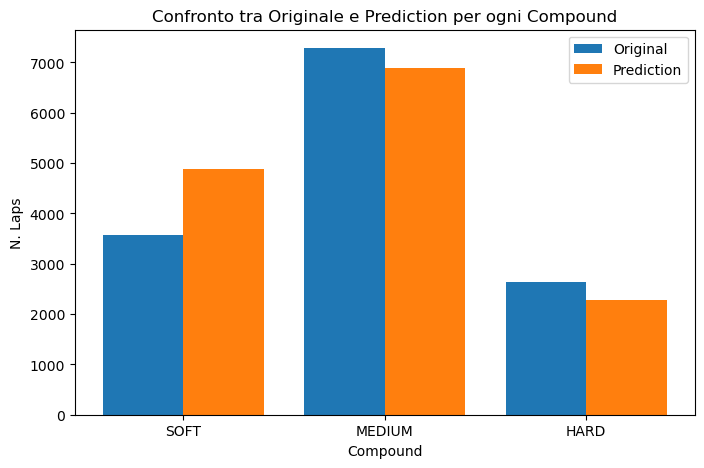

In [30]:
df_show_orig = df_original_group[df_original_group['Stint'] == 'Stint_1']
df_show_pred = df_prediction_group[df_prediction_group['Stint'] == 'Stint_1']

compound_mapping = {'CompoundBest_1':'SOFT', 'CompoundBest_2':'MEDIUM', 'CompoundBest_3':'HARD'}
df_show_orig['Compound'] = df_show_orig['Compound'].map(compound_mapping)
df_show_pred['Compound'] = df_show_pred['Compound'].map(compound_mapping)

merged = df_show_orig.merge(df_show_pred, on='Compound', suffixes=('_df_show', '_df_pred'))

# Imposta le posizioni delle categorie
x = np.arange(len(merged['Compound']))  # posizioni delle categorie
larghezza = 0.4  # larghezza delle barre

# Plot delle barre affiancate con colori diversi
fig, ax = plt.subplots(figsize=(8, 5))
bar1 = ax.bar(x - larghezza/2, merged['conteggio_df_show'], larghezza, label='Original')
bar2 = ax.bar(x + larghezza/2, merged['conteggio_df_pred'], larghezza, label='Prediction')

# Aggiungi etichette e legende
ax.set_xlabel('Compound')
ax.set_ylabel('N. Laps')
ax.set_title('Confronto tra Originale e Prediction per ogni Compound')
ax.set_xticks(x)
ax.set_xticklabels(merged['Compound'])
ax.legend()

# Mostra il grafico
plt.show()

In [ ]:
plt.figure(figsize = (15, 5))
plt.plot(original, label="Original value")
plt.plot(prediction, label="Prediction value")
plt.xlabel("Stint")
plt.ylabel("N. Use Compound")
plt.title("Comparison true vs. predicted test set")
plt.legend()
plt.show()

In [ ]:
look_back = 2

# shift train predictions for plotting
trainPredictPlot = np.empty_like(df_final)
trainPredictPlot[:, :] = np.nan
trainPredictPlot[look_back:len(trainPredict)+look_back, :] = trainPredict

# shift test predictions for plotting
testPredictPlot = np.empty_like(df_final)
testPredictPlot[:, :] = np.nan
testPredictPlot[len(trainPredict)+(look_back*2)+1:len(dataset)-1, :] = testPredict
# plot baseline and predictions
plt.plot(scaler.inverse_transform(dataset))
plt.plot(trainPredictPlot)
plt.plot(testPredictPlot)
plt.show()